# Satellite image SVD

## Download images

Download three 512 × 512 Sentinel-2 RGB crops at 10 m/pixel from [Planetary Computer](https://planetarycomputer.microsoft.com/dataset/sentinel-2-l2a).

In [10]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import planetary_computer
import rasterio
from PIL import Image
from pystac_client import Client
from rasterio.warp import transform
from rasterio.windows import Window

LAB_DIR = Path("lab_1") if Path("lab_1/algebra.ipynb").exists() else Path(".")
IMAGE_DIR = LAB_DIR / "images"

In [11]:
IMAGE_SIZE = 512
sites = {
    "niepolomice": ("Niepołomice", 20.33, 50.03),
    "cracow": ("Kraków", 19.94, 50.06),
    "baltic": ("Baltic Sea", 18.50, 54.85),
}

IMAGE_DIR.mkdir(exist_ok=True)
catalog = None
for name, (label, lon, lat) in sites.items():
    path = IMAGE_DIR / f"{name}.png"
    if path.exists():
        continue
    if catalog is None:
        catalog = Client.open(
            "https://planetarycomputer.microsoft.com/api/stac/v1",
            modifier=planetary_computer.sign_inplace,
        )
    item = next(catalog.search(
        collections=["sentinel-2-l2a"],
        intersects={"type": "Point", "coordinates": [lon, lat]},
        datetime="2024-06-01/2024-08-31",
        query={"eo:cloud_cover": {"lt": 10}},
        sortby=[{"field": "properties.eo:cloud_cover", "direction": "asc"}],
        max_items=1,
    ).items())
    with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR"):
        with rasterio.open(item.assets["visual"].href) as src:
            x, y = transform("EPSG:4326", src.crs, [lon], [lat])
            row, col = src.index(x[0], y[0])
            window = Window(col - IMAGE_SIZE // 2, row - IMAGE_SIZE // 2, IMAGE_SIZE, IMAGE_SIZE)
            rgb = src.read([1, 2, 3], window=window)
    Image.fromarray(rgb.transpose(1, 2, 0)).save(path)

print("Images saved in", IMAGE_DIR)

Images saved in images


## Singular Value Decomposition

Convert each image to grayscale and compute its SVD.

In [12]:
images = {}
for name in sites:
    with Image.open(IMAGE_DIR / f"{name}.png") as img:
        images[name] = np.asarray(img.convert("L"), dtype=float)

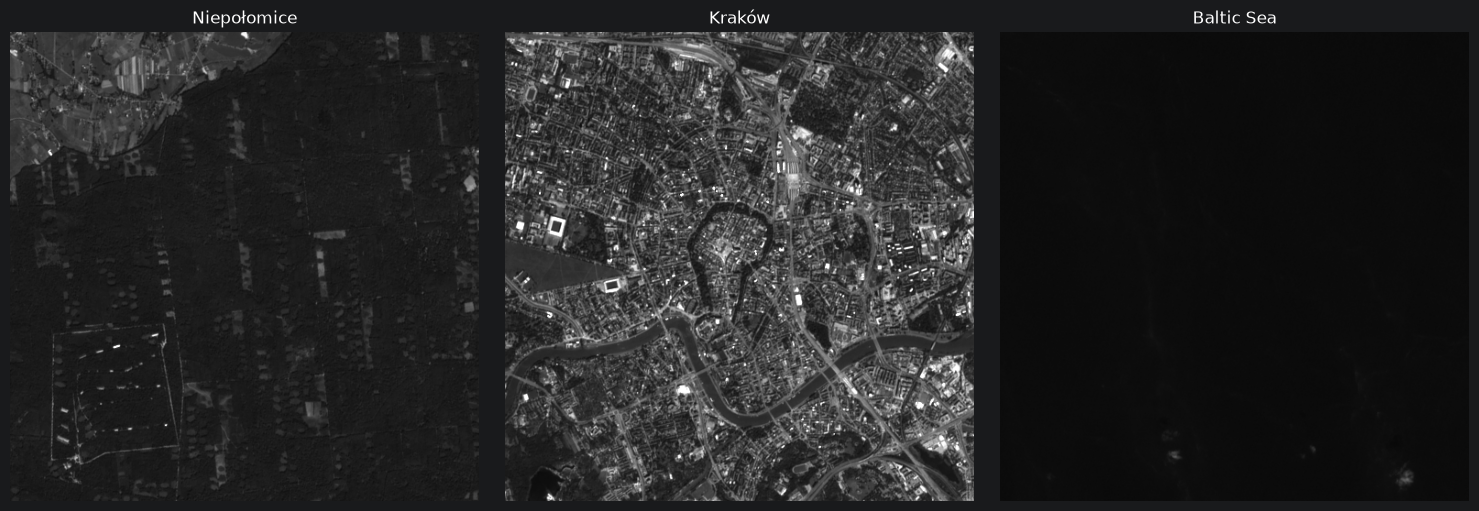

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (name, imgmat) in zip(axes, images.items()):
    ax.imshow(imgmat, cmap="gray", vmin=0, vmax=255)
    ax.set_title(sites[name][0])
    ax.axis("off")
plt.tight_layout()
plt.show()

### SVD

Reconstruct each image using its largest singular value.

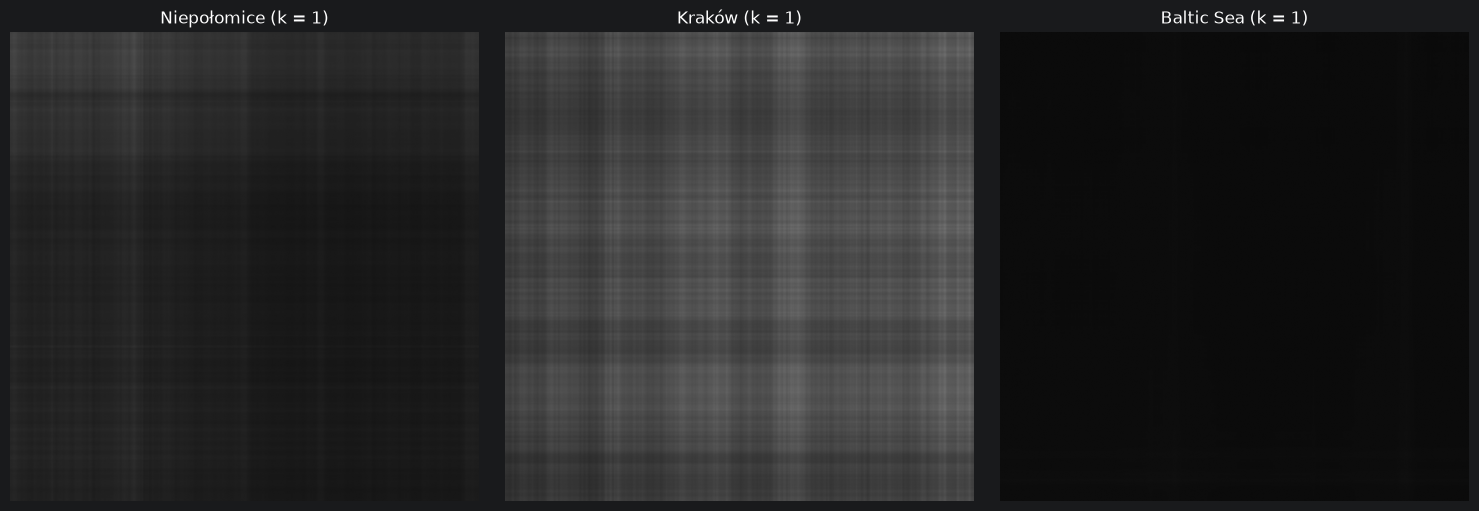

In [14]:
svd_results = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (name, imgmat) in zip(axes, images.items()):
    U, sigma, Vt = np.linalg.svd(imgmat, full_matrices=False)
    svd_results[name] = (U, sigma, Vt)
    reconstimg = U[:, :1] @ np.diag(sigma[:1]) @ Vt[:1, :]
    ax.imshow(reconstimg, cmap="gray", vmin=0, vmax=255)
    ax.set_title(sites[name][0] + " (k = 1)")
    ax.axis("off")
plt.tight_layout()
plt.show()

### Singular values

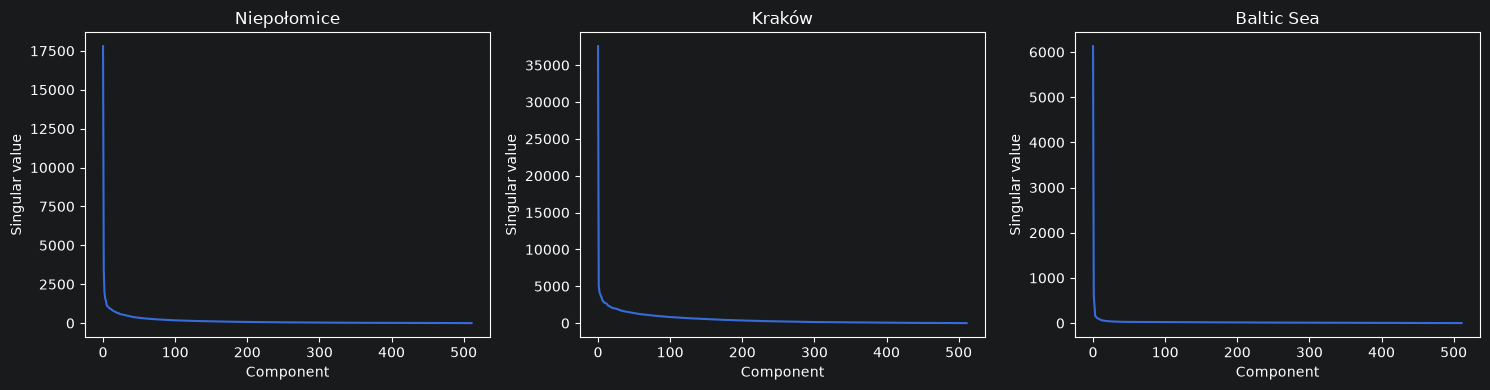

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, (_, sigma, _)) in zip(axes, svd_results.items()):
    ax.plot(sigma)
    ax.set_title(sites[name][0])
    ax.set_xlabel("Component")
    ax.set_ylabel("Singular value")
plt.tight_layout()
plt.show()

### Selected k

Smallest values from the earlier tests with SSIM ≥ 0.98: forest **200**, city **300**, sea **1**.
Keep these reconstructions in `reconstructed_images`.

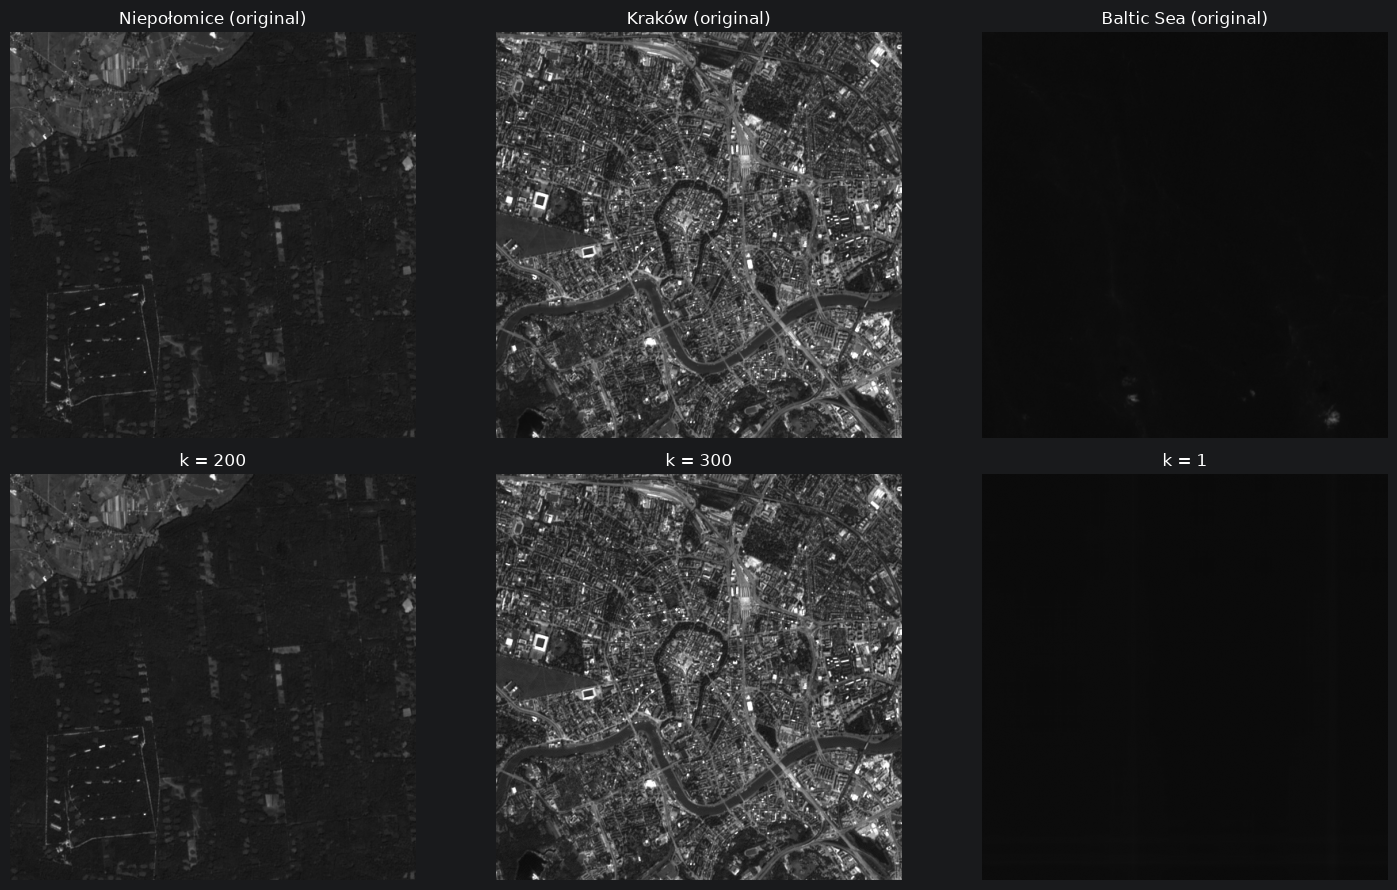

In [16]:
k_values = {"niepolomice": 200, "cracow": 300, "baltic": 1}
reconstructed_images = {}

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for col, (name, imgmat) in enumerate(images.items()):
    U, sigma, Vt = svd_results[name]
    k = k_values[name]
    reconstimg = U[:, :k] @ np.diag(sigma[:k]) @ Vt[:k, :]
    reconstructed_images[name] = reconstimg
    axes[0, col].imshow(imgmat, cmap="gray", vmin=0, vmax=255)
    axes[0, col].set_title(sites[name][0] + " (original)")
    axes[1, col].imshow(reconstimg, cmap="gray", vmin=0, vmax=255)
    axes[1, col].set_title(f"k = {k}")
    axes[0, col].axis("off")
    axes[1, col].axis("off")
plt.tight_layout()
plt.show()

### Skipping the first 10 components

Compare components 1–k with 11–(k+10), keeping the same k.
Use the same 0–255 display range for both.

Niepołomice: MSE 1.27 -> 1307.03
Kraków: MSE 3.66 -> 5838.16
Baltic Sea: MSE 2.90 -> 146.21


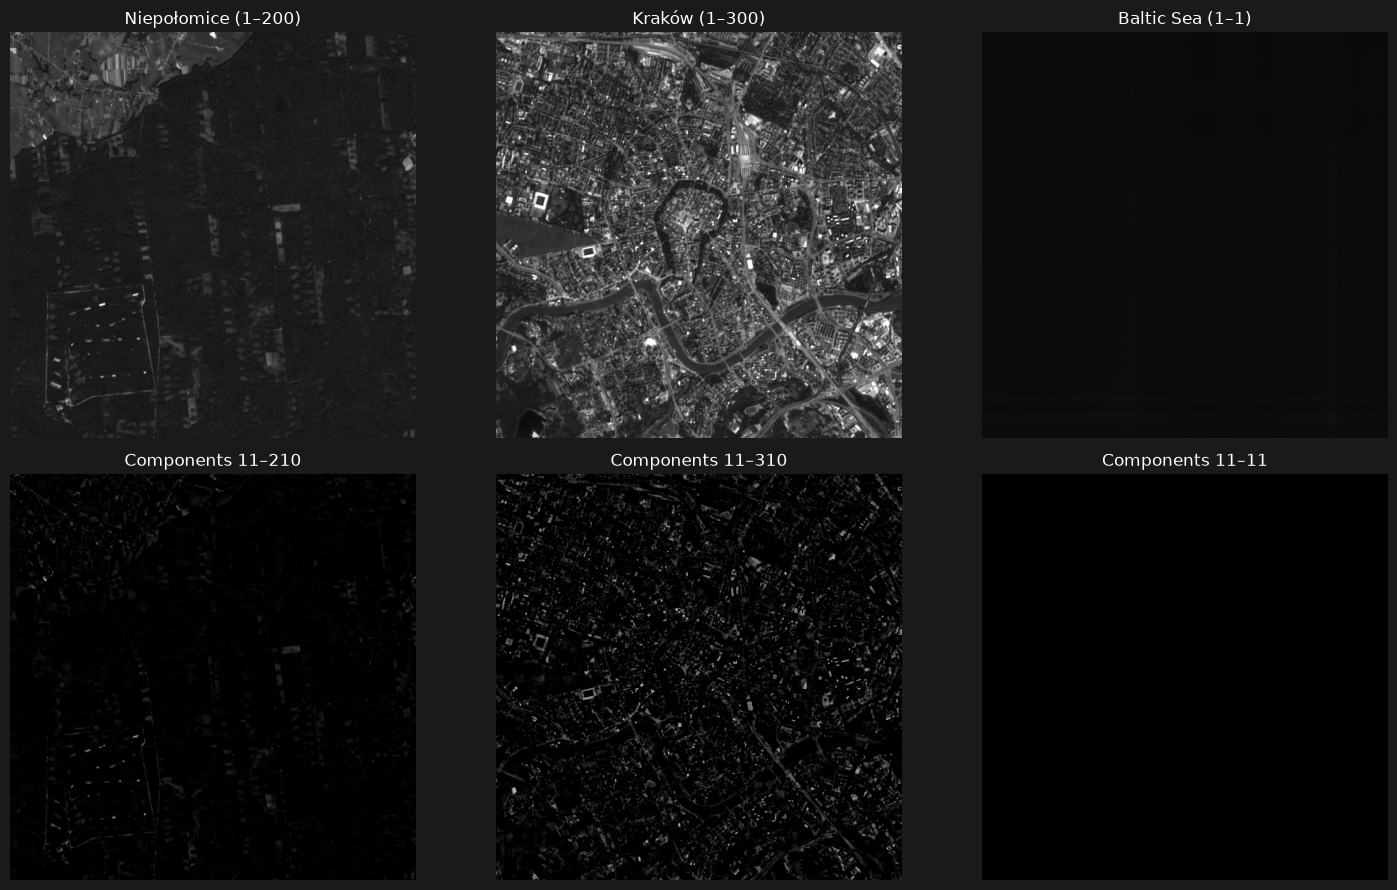

In [17]:
skipped_images = {}
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for col, name in enumerate(images):
    U, sigma, Vt = svd_results[name]
    k = k_values[name]
    skipped = U[:, 10:k+10] @ np.diag(sigma[10:k+10]) @ Vt[10:k+10, :]
    skipped_images[name] = skipped
    axes[0, col].imshow(reconstructed_images[name], cmap="gray", vmin=0, vmax=255)
    axes[0, col].set_title(sites[name][0] + f" (1–{k})")
    axes[1, col].imshow(skipped, cmap="gray", vmin=0, vmax=255)
    axes[1, col].set_title(f"Components 11–{k+10}")
    axes[0, col].axis("off")
    axes[1, col].axis("off")
    original = images[name]
    mse_first = np.mean((original - reconstructed_images[name]) ** 2)
    mse_skipped = np.mean((original - skipped) ** 2)
    print(f"{sites[name][0]}: MSE {mse_first:.2f} -> {mse_skipped:.2f}")
plt.tight_layout()
plt.show()

**Skipping the first 10 components did not improve any image.**

- Niepołomice: MSE increased from **1.27** to **1307.03**.
- Kraków: MSE increased from **3.66** to **5838.16**.
- Baltic Sea: MSE increased from **2.90** to **146.21**.

The images lose brightness and large structures - some edges and texture remain.
The leading k components give the smallest squared reconstruction error.